In [27]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm   # norm.cdf is N(x)

S0 = 100          # starting price
K = 100           # strike
sigma = 0.20      # volatility
T = 21 / 252      # one month in years
n_paths = 10_000
M = 1680          # fine grid steps (divisible by 5, 21, 84, 336)

rng = np.random.default_rng(42)   # fixed seed so results repeat every run

In [28]:
def simulate_paths(S0, sigma, T, M, n_paths, rng):
    dt = T / M
    Z = rng.standard_normal((n_paths, M))                       # one random draw per path per step
    log_steps = -0.5 * sigma**2 * dt + sigma * np.sqrt(dt) * Z  # the exponent above
    log_paths = np.cumsum(log_steps, axis=1)                    # add up steps along each row
    log_paths = np.hstack([np.zeros((n_paths, 1)), log_paths])  # put the start (log 1 = 0) in front
    return S0 * np.exp(log_paths)

S = simulate_paths(S0, sigma, T, M, n_paths, rng)

In [29]:
def bs_call(S, K, sigma, tau):
    if tau == 0:                                  # at expiry: no formula, use the payoff
        return np.maximum(S - K, 0), (S > K).astype(float)
    d1 = (np.log(S / K) + 0.5 * sigma**2 * tau) / (sigma * np.sqrt(tau))
    d2 = d1 - sigma * np.sqrt(tau)
    price = S * norm.cdf(d1) - K * norm.cdf(d2)
    delta = norm.cdf(d1)
    return price, delta

C0, delta0 = bs_call(np.array(100.0), K, sigma, T)
print(C0, delta0)   # should be about 2.30 and 0.51

2.3029744678024286 0.5115148723390122


In [30]:
C0 = float(C0)   # premium, from cell 3

def pnl_one_path_loop(path, n, hedge=True):
    step = M // n             # how many fine steps between rebalances
    S_reb = path[::step]      # prices at t0, t1, ..., tn  (n+1 prices)
    dt = T / n                # time between rebalances

    pnl = C0                  # start with the premium
    for i in range(n):
        tau = T - i * dt                          # time left to expiry
        _, delta = bs_call(S_reb[i], K, sigma, tau)
        if not hedge:
            delta = 0.0
        pnl += delta * (S_reb[i+1] - S_reb[i])    # gain/loss on shares this interval
    pnl -= max(S_reb[-1] - K, 0)                  # pay the option payoff
    return pnl

In [31]:
path = S[0]   # first simulated path

# never hedge: must equal premium minus payoff EXACTLY
a = pnl_one_path_loop(path, 21, hedge=False)
b = C0 - max(path[-1] - K, 0)
print(a, b, a - b)   # difference should be exactly 0

# hedged: should be small, roughly between -1 and +1
for p in range(5):
    print(pnl_one_path_loop(S[p], 21))

2.3029744678024286 2.3029744678024286 0.0
0.37083409839623543
0.021922795292634484
-0.25206062797042966
-0.19808662598440385
-0.07741353000228983


In [32]:
n = 3
step = M // n
S_reb = path[::step]
dt = T / n
print("prices:", S_reb)

total = C0
for i in range(n):
    tau = T - i * dt
    _, d = bs_call(S_reb[i], K, sigma, tau)
    gain = d * (S_reb[i+1] - S_reb[i])
    total += gain
    print(f"i={i}  tau={tau:.5f}  S={S_reb[i]:.4f}  delta={d:.6f}  gain={gain:.6f}")
payoff = max(S_reb[-1] - K, 0)
total -= payoff
print("payoff:", payoff, " P&L:", total)
print("function:", pnl_one_path_loop(path, 3))   # must match total

prices: [100.          98.55340027  96.97548305  92.46279929]
i=0  tau=0.08333  S=100.0000  delta=0.511515  gain=-0.739957
i=1  tau=0.05556  S=98.5534  delta=0.387615  gain=-0.611624
i=2  tau=0.02778  S=96.9755  delta=0.182814  gain=-0.824982
payoff: 0  P&L: 0.1264113480581066
function: 0.1264113480581066


In [33]:
def pnl_vectorized(S, n, hedge=True):
    step = M // n
    S_reb = S[:, ::step]                 # all paths, every step-th column -> (10000, n+1)
    dt = T / n
    taus = T - np.arange(n) * dt         # time left at each rebalance -> (n,)
    S_now = S_reb[:, :-1]                # prices at t0..t(n-1), where you set delta -> (10000, n)

    d1 = (np.log(S_now / K) + 0.5 * sigma**2 * taus) / (sigma * np.sqrt(taus))
    deltas = norm.cdf(d1)                # delta for every path at every rebalance -> (10000, n)
    if not hedge:
        deltas = np.zeros_like(deltas)

    dS = np.diff(S_reb, axis=1)          # S(i+1) - S(i) for every interval -> (10000, n)
    payoff = np.maximum(S_reb[:, -1] - K, 0)   # payoff for every path -> (10000,)

    return C0 + (deltas * dS).sum(axis=1) - payoff

In [34]:
for n in [3, 5, 21, 84, 336]:
    v = pnl_vectorized(S, n)
    l = np.array([pnl_one_path_loop(S[p], n) for p in range(100)])   # loop on first 100 paths
    print(n, np.max(np.abs(v[:100] - l)))

# never-hedge check, all paths
v = pnl_vectorized(S, 21, hedge=False)
print(np.max(np.abs(v - (C0 - np.maximum(S[:, -1] - K, 0)))))

v = pnl_vectorized(S, 21)
print(v[:5])
print(v.shape)

3 8.881784197001252e-16
5 1.7763568394002505e-15
21 3.552713678800501e-15
84 7.105427357601002e-15
336 1.2434497875801753e-14
0.0
[ 0.3708341   0.0219228  -0.25206063 -0.19808663 -0.07741353]
(10000,)


In [35]:
freqs = [5, 21, 84, 336]
means = []
stds = []

for n in freqs:
    pnl = pnl_vectorized(S, n)        # P&L for all 10,000 paths at this frequency
    means.append(pnl.mean())
    stds.append(pnl.std())
    print(f"n={n:4d}  mean={pnl.mean():+.4f}  std={pnl.std():.4f}")

n=   5  mean=+0.0075  std=0.8432
n=  21  mean=+0.0064  std=0.4218
n=  84  mean=+0.0050  std=0.2158
n= 336  mean=-0.0003  std=0.1106


In [36]:
def pnl_vec_fees(S, n, fee_rate=0.0):
    step = M // n
    S_reb = S[:, ::step]
    dt = T / n
    taus = T - np.arange(n) * dt
    S_now = S_reb[:, :-1]

    d1 = (np.log(S_now / K) + 0.5 * sigma**2 * taus) / (sigma * np.sqrt(taus))
    deltas = norm.cdf(d1)
    dS = np.diff(S_reb, axis=1)
    payoff = np.maximum(S_reb[:, -1] - K, 0)

    # --- fees ---
    zeros = np.zeros((S.shape[0], 1))
    holdings = np.hstack([zeros, deltas, zeros])   # 0, Δ0, ..., Δ(n-1), 0  -> (10000, n+2)
    trades = np.diff(holdings, axis=1)             # shares traded at t0, t1, ..., T -> (10000, n+1)
    fees = fee_rate * (np.abs(trades) * S_reb).sum(axis=1)

    return C0 + (deltas * dS).sum(axis=1) - payoff - fees

In [37]:
def pnl_loop_fees(path, n, fee_rate=0.0):
    step = M // n
    S_reb = path[::step]
    dt = T / n
    pnl = C0
    prev = 0.0                                     # start holding 0 shares
    for i in range(n):
        tau = T - i * dt
        _, d = bs_call(S_reb[i], K, sigma, tau)
        pnl -= fee_rate * abs(d - prev) * S_reb[i] # fee on this trade
        pnl += d * (S_reb[i+1] - S_reb[i])
        prev = d
    pnl -= fee_rate * abs(prev) * S_reb[-1]        # fee to sell everything at T
    pnl -= max(S_reb[-1] - K, 0)
    return pnl

for n in [3, 21, 336]:
    v = pnl_vec_fees(S, n, 0.001)
    l = np.array([pnl_loop_fees(S[p], n, 0.001) for p in range(100)])
    print(n, np.max(np.abs(v[:100] - l)))

# with fee_rate = 0 it must equal the old version
print(np.max(np.abs(pnl_vec_fees(S, 21, 0.0) - pnl_vectorized(S, 21))))

3 1.4432899320127035e-15
21 4.107825191113079e-15
336 2.3092638912203256e-14
0.0


In [38]:
freqs = [5, 21, 84, 336, 1680]
std_nofee, std_fee = [], []
mean_nofee, mean_fee = [], []

for n in freqs:
    a = pnl_vec_fees(S, n, 0.0)
    b = pnl_vec_fees(S, n, 0.001)
    mean_nofee.append(a.mean()); std_nofee.append(a.std())
    mean_fee.append(b.mean());   std_fee.append(b.std())
    print(f"n={n:5d} | no fee: mean={a.mean():+.4f} std={a.std():.4f} | fee: mean={b.mean():+.4f} std={b.std():.4f}")

n=    5 | no fee: mean=+0.0075 std=0.8432 | fee: mean=-0.1547 std=0.8553
n=   21 | no fee: mean=+0.0064 std=0.4218 | fee: mean=-0.2376 std=0.4373
n=   84 | no fee: mean=+0.0050 std=0.2158 | fee: mean=-0.3875 std=0.2549
n=  336 | no fee: mean=-0.0003 std=0.1106 | fee: mean=-0.6869 std=0.2573
n= 1680 | no fee: mean=+0.0006 std=0.0493 | fee: mean=-1.4092 std=0.4992


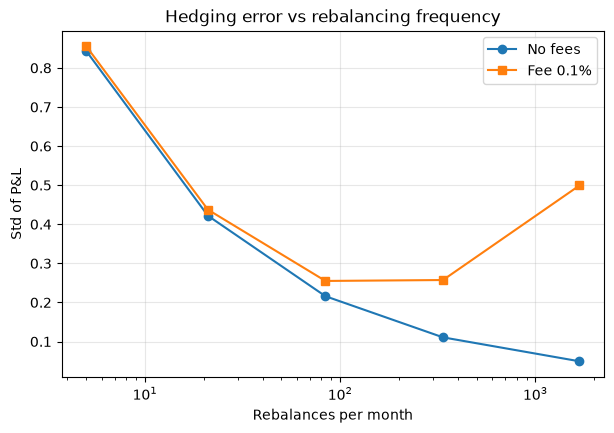

In [39]:
plt.figure(figsize=(7, 4.5))
plt.plot(freqs, std_nofee, "o-", label="No fees")
plt.plot(freqs, std_fee, "s-", label="Fee 0.1%")
plt.xscale("log")
plt.xlabel("Rebalances per month")
plt.ylabel("Std of P&L")
plt.title("Hedging error vs rebalancing frequency")
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig("std_vs_freq.png", dpi=150, bbox_inches="tight")
plt.show()

slope: -0.48706774582915746


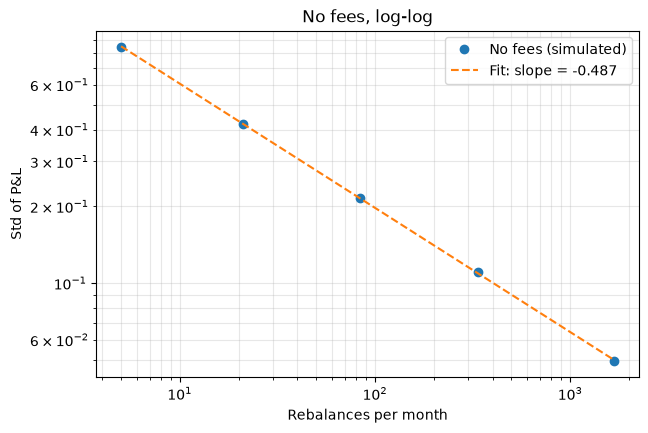

In [40]:
slope, intercept = np.polyfit(np.log(freqs), np.log(std_nofee), 1)
print("slope:", slope)

plt.figure(figsize=(7, 4.5))
plt.loglog(freqs, std_nofee, "o", label="No fees (simulated)")
xs = np.array(freqs)
plt.loglog(xs, np.exp(intercept) * xs**slope, "--", label=f"Fit: slope = {slope:.3f}")
plt.xlabel("Rebalances per month")
plt.ylabel("Std of P&L")
plt.title("No fees, log-log")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.savefig("loglog_nofee.png", dpi=150, bbox_inches="tight")
plt.show()

In [42]:
'''
what surprised me was the fact that on of the most challenging parts of hedging is finding the importance of fees. 
fees have a large effect on the edging error, as compared to no fees. 
'''